<div align="center">

# <span style="color: #3498db;">CA2 - Genetic & Game</span>

**<span style="color:rgb(247, 169, 0);">[Sadegh Samadi]</span> - <span style="color:rgb(143, 95, 195);">[810102588]</span>**

</div>


<div style="font-family: Arial, sans-serif; line-height: 1.6;">

### 📊 Matplotlib – Data Visualization in Python  

matplotlib is a python library that is mainly used for data visualization. This library allows you to plot different type of figures including scatters and histograms. In the first part of this project you are supposed to implement a genetic algorithm. To visualize plots that are required in the project description use plotting as much as you can because it gives a great insight on what is happening during each run. It also helps you to compare your results whenevever you want to understand effect of different parameters during different runs.
For more information, check [this notebook](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/04.00-Introduction-To-Matplotlib.ipynb) and visit [the website](https://matplotlib.org/stable/tutorials/pyplot.html#sphx-glr-tutorials-pyplot-py).

In [8]:
import matplotlib.pyplot as plt

# <span style="color: #3498db;">Genetic Algorithm</span>

In [9]:
import random
import itertools
import numpy as np

In [10]:
# algorithm parameters
numCoeffs = 41
populationSize = 1000
generations = 100
mutationRate = 0.15
functionRange = (-np.pi, np.pi)
sampleCount = 100
limitA = 1.5 


In [11]:
# These functions are given as samples to use in the algorithm
def getTargetFunction(functionName="sin_cos"):
    def sinCosFunction(t):
        """Target function: sin(2πt) + 0.5*cos(4πt)."""
        return np.sin(2 * np.pi * t) + 0.5 * np.cos(4 * np.pi * t)

    def linearFunction(t):
        """Simple linear function: y = 2t + 1."""
        return 2 * t + 1

    def quadraticFunction(t):
        """Quadratic function: y = 4t^2 - 4t + 2."""
        return 4 * (t**2) - 4 * t + 2

    def cubicFunction(t):
        """Cubic function: y = 8t^3 - 12t^2 + 6t."""
        return 8 * (t**3) - 12 * (t**2) + 6 * t

    def gaussianFunction(t):
        """Gaussian function centered at t=0.5."""
        mu = 0.5
        sigma = 0.1  # Adjust sigma to control the width of the peak
        return np.exp(-((t - mu) ** 2) / (2 * sigma**2))

    def squareWaveFunction(t):
        """approximationimation of a square wave. Smoothed for better Fourier approximationimation."""
        return 0.5 * (np.sign(np.sin(2 * np.pi * t)) + 1)

    def sawtoothFunction(t):
        """Sawtooth wave, normalized to [0, 1]."""
        return (t * 5) % 1

    def complexFourierFunction(t):
        return (
            np.sin(2 * np.pi * t)
            + 0.3 * np.cos(4 * np.pi * t)
            + 0.2 * np.sin(6 * np.pi * t)
            + 0.1 * np.cos(8 * np.pi * t)
        )

    def polynomialFunction(t):
        return 10 * (t**5) - 20 * (t**4) + 15 * (t**3) - 4 * (t**2) + t + 0.5

    functionOptions = {
        "sin_cos": sinCosFunction,
        "linear": linearFunction,
        "quadratic": quadraticFunction,
        "cubic": cubicFunction,
        "gaussian": gaussianFunction,
        "square_wave": squareWaveFunction,
        "sawtooth": sawtoothFunction,
        "complex_fourier": complexFourierFunction,
        "polynomial": polynomialFunction,
    }

    selectedFunction = functionOptions.get(functionName.lower())
    if selectedFunction:
        return selectedFunction

In [12]:
numCoeffs = 41
mutationRate = 0.02
functionRange = (-np.pi, np.pi)
sampleCount = 100
tournamentSize = 2
eliteCount = 2

def calculate_fourier_series(coeffs, tsamples):
    n = np.arange(1, 21) 
    ret = coeffs[0] / 2.0
    ret += np.dot(np.sin(np.outer(tsamples, n)), coeffs[1:21])
    ret += np.dot(np.cos(np.outer(tsamples, n)), coeffs[21:41])
    return ret 

def inverse(RMSE): 
    return 1.0 / (1.0 + RMSE)

def calculate_RMSE(fapproximations, fsamples): 
    MSE = np.mean((fapproximations - fsamples) ** 2)
    return inverse(np.sqrt(MSE))

def calculate_R2(fapproximations, fsamples):
    return np.maximum(1.0 - np.sum((fsamples - fapproximations) ** 2) / (np.sum((fsamples - np.mean(fsamples)) ** 2) + 1e-8), 0) 

def calculate_MAE(fapproximations, fSamples):
    return inverse(np.mean(np.abs(fapproximations - fSamples)))

def calculate_corr(fapproximations, fsamples):
    r = np.corrcoef(fapproximations, fsamples)[0, 1]
    return (r + 1) / 2.0

def calculate_fitness(population, fsamples, tsamples, fitness_func): 
    fitness = np.zeros(len(population))
    for i in range(len(population)): 
        fapproximations = calculate_fourier_series(population[i], tsamples)
        fitness[i] = fitness_func(fapproximations, fsamples)
    return fitness

def tournament_selection(population, fitness): 
    candidate = np.random.choice(len(population), size = tournamentSize, replace = False)
    candidate_fitness = fitness[candidate] 
    return population[np.argmax(candidate_fitness)]

def roulette_wheel_selection(population, fitness):
    total = np.sum(fitness)
    if total == 0:
        idx = np.random.randint(len(population))
    else:
        probabilities = fitness / total
        idx = np.random.choice(len(population), p = probabilities)
    return population[idx]

def roulette_wheel_selection_by_rank(population, fitness):
    order = np.argsort(fitness)
    ranks = np.empty_like(order)
    ranks[order] = np.arange(1, len(fitness)+1)
    probabilities = ranks / np.sum(ranks)
    idx = np.random.choice(len(population), p=probabilities)
    return population[idx]

def uniform_crossover(parent1, parent2):
    mask = np.random.rand(numCoeffs) < 0.5
    return np.where(mask, parent1, parent2)

def one_point_crossover(parent1, parent2):
    point = np.random.randint(1, numCoeffs)
    child = np.zeros(len(parent1))
    child[:point] = parent1[:point]
    child[point:] = parent2[point:]
    return child

def two_point_crossover(parent1, parent2):
    point1 = np.random.randint(1, numCoeffs)
    point2 = np.random.randint(1, numCoeffs)
    if (point1 > point2):
        temp = point1
        point1 = point2
        point2 = temp
    child = np.zeros(len(parent1))
    child[:point1] = parent1[:point1]
    child[point1:point2] = parent2[point1:point2]
    child[point2:] = parent1[point2:]
    return child

def mutate(child, limitA):
    mask = np.random.rand(numCoeffs) < mutationRate
    child[mask] = np.random.uniform(low = -limitA, high = limitA, size = np.sum(mask))
    return child

def GA(tsamples, fsamples, num_generations = 300, populationSize = 100, fitness_func = calculate_RMSE, crossover_func = uniform_crossover, selection_func = tournament_selection):
    limitA = np.max(np.abs(fsamples))
    population = np.random.uniform(low = -limitA, high = limitA, size = (populationSize, numCoeffs))
    fitness_history = []
    for generation in range(num_generations):
        fitness = calculate_fitness(population, fsamples, tsamples, fitness_func)
        fitness_history.append(np.max(fitness))
        new_population = np.zeros((populationSize, numCoeffs))            
        sorted_indices = np.argsort(fitness)
        new_population[:eliteCount] = population[sorted_indices[-eliteCount:]]            
        for j in range(eliteCount, populationSize):
            parent1 = selection_func(population, fitness)
            parent2 = selection_func(population, fitness)
            child = crossover_func(parent1, parent2)
            child = mutate(child, limitA)
            new_population[j] = child
        population = new_population    
    fitness = calculate_fitness(population, fsamples, tsamples, fitness_func)
    best_chromosome = population[np.argmax(fitness)]
    approximation = calculate_fourier_series(best_chromosome, tsamples)    
    return approximation, fitness_history

<div style="color:rgb(235, 66, 32); font-weight: bold;">⚠️ Important Note:</div>  

Using **NumPy arrays** allows you to perform operations on vectors **more efficiently** and **faster**.

**Avoid using `for` loops** whenever possible, as vectorized operations in NumPy are **optimized for performance** and significantly reduce execution time.  


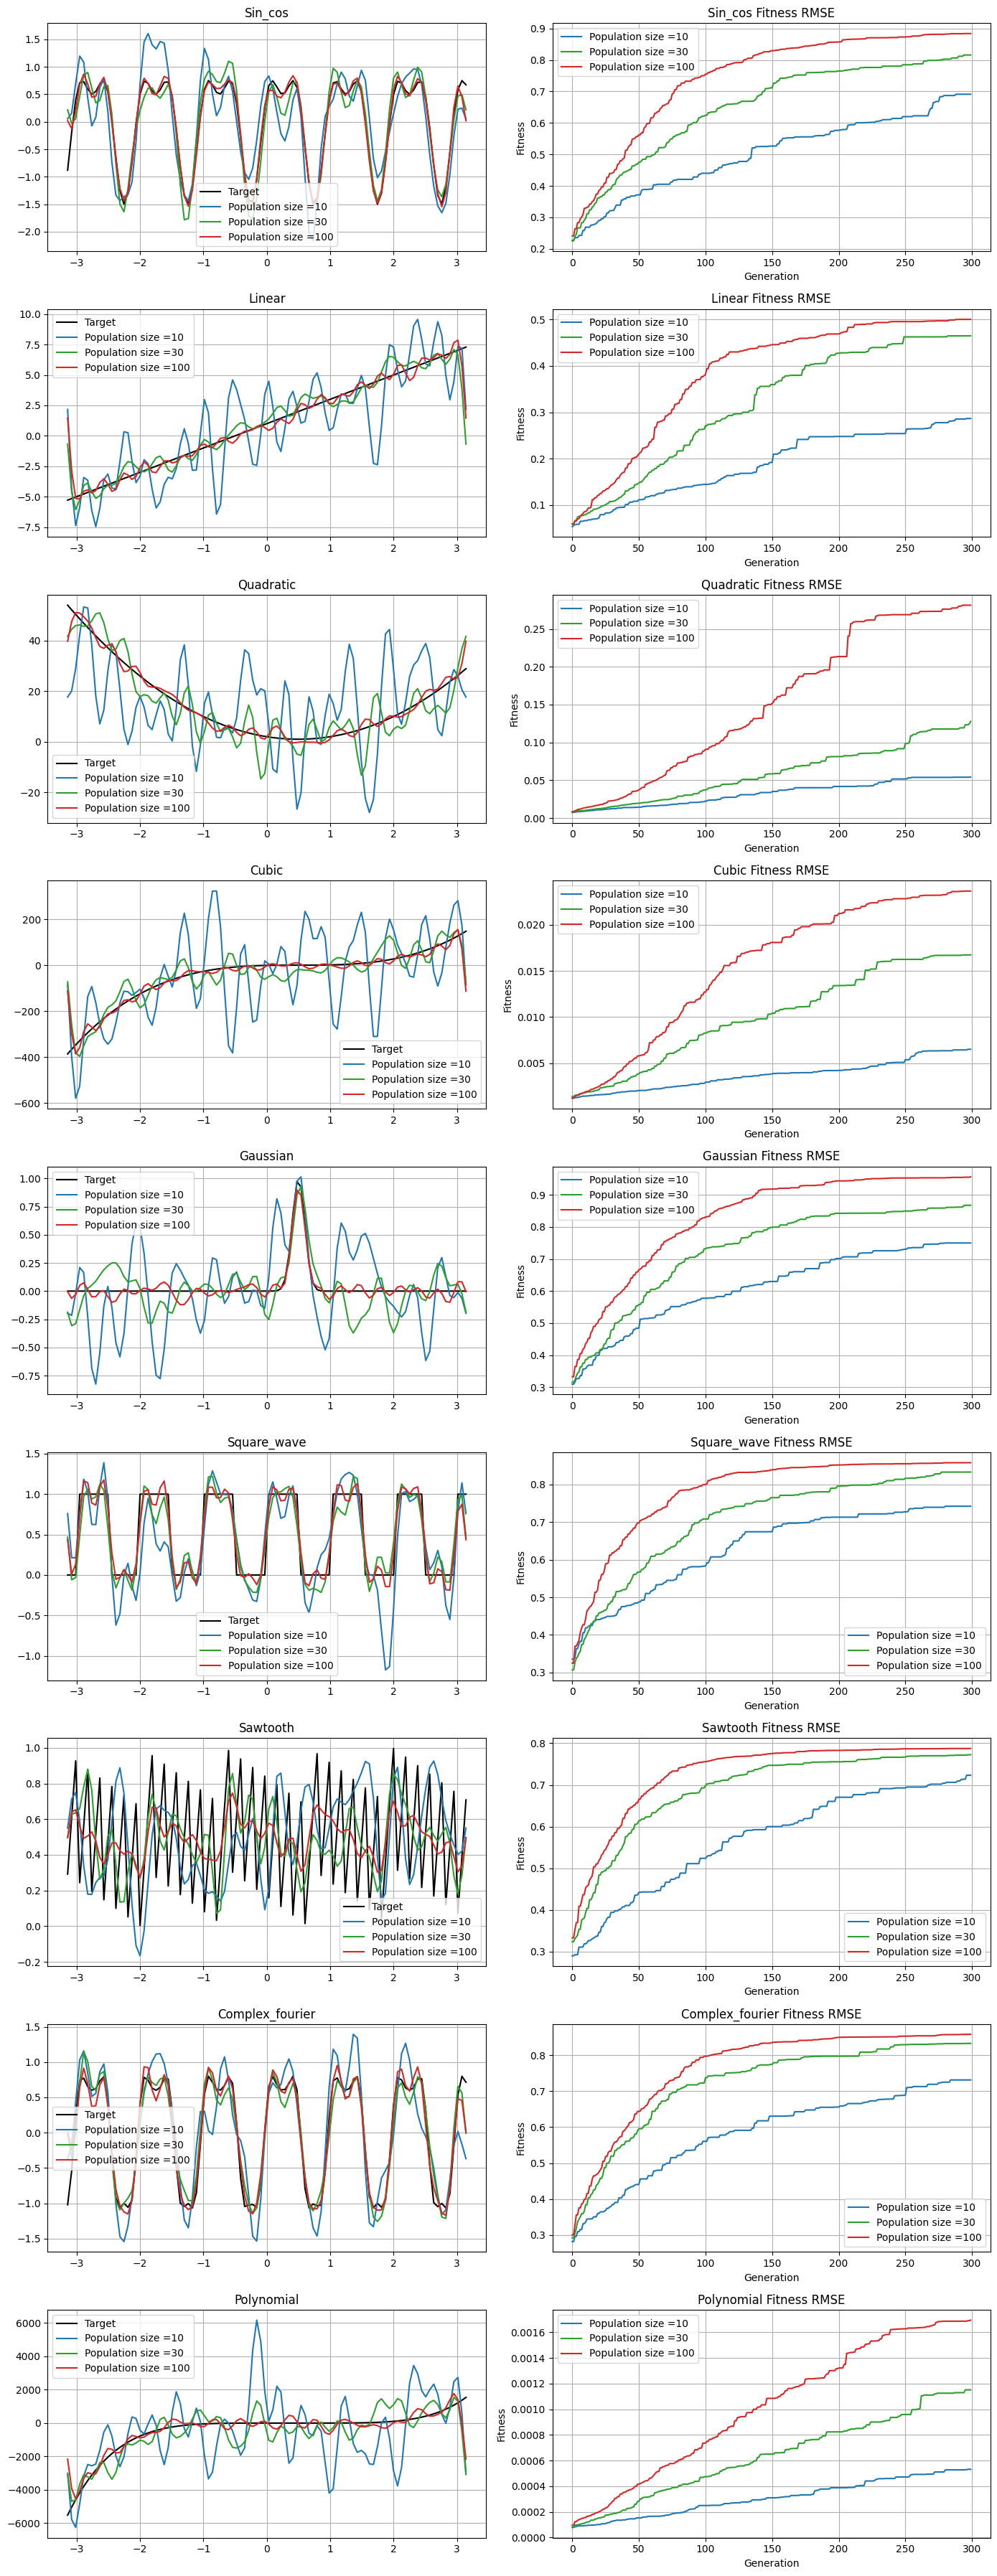

In [13]:
function_names = ["sin_cos", "linear", "quadratic", "cubic", "gaussian", "square_wave", "sawtooth", "complex_fourier", "polynomial"]
numRows = len(function_names)
numCols = 2
fig, axs = plt.subplots(numRows, numCols, figsize = (14, 4 * numRows))
populationSizes = [10, 30, 100]
colors = ['C0', 'C2', 'C3']

for i in range(len(function_names)):
    function_name = function_names[i]
    tSamples = np.linspace(functionRange[0], functionRange[1], sampleCount)
    fSamples = getTargetFunction(function_name)(tSamples)
    limitA = np.max(np.abs(fSamples))
    approximations = []
    fitness_histories = []    
    for population_size in populationSizes:
        approximation, fitness_history = GA(tsamples = tSamples, fsamples = fSamples, populationSize = population_size, fitness_func = calculate_RMSE, crossover_func = uniform_crossover, selection_func = tournament_selection)    
        approximations.append(approximation)
        fitness_histories.append(fitness_history)

    axs[i, 0].plot(tSamples, fSamples, 'k-', label = "Target") 
    for j in range(len(populationSizes)):
        axs[i, 0].plot(tSamples, approximations[j], color = colors[j], label = "Population size =" + str(populationSizes[j]))
    axs[i, 0].set_title(function_name.capitalize())
    axs[i, 0].legend()
    axs[i, 0].grid(True)
    
    for j in range(len(populationSizes)):
        axs[i, 1].plot(fitness_histories[j], color = colors[j], label = "Population size =" + str(populationSizes[j]))
    axs[i, 1].set_title(function_name.capitalize() + " Fitness RMSE")
    axs[i, 1].set_xlabel("Generation")
    axs[i, 1].set_ylabel("Fitness")
    axs[i, 1].legend()
    axs[i, 1].grid(True)

plt.tight_layout()
plt.show()


# بخش ۲
#### همانطور که مشاهده میشود جمعیت بیشتر در تمامی توابع باعث میشود تا تخمین دقیقتری انجام شود و دلیل آن هم بدیهی است که حالت های بیشتری ساخته میشود و چون این جمعیت در همه نسل ها ثابت است و تعداد crossover ها را بیشتر میکند باز هم به اینکه به حالت های بیشتری برسیم را تقویت میکند و دیدن حالت های متفاوت باعث میشود که کمتر در ماکسیمم های محلی گیر بیفتیم. از طرف  دیگر هم با توجه به رشد fitness ها میتوانیم متوجه تاثیر مستقیم جمعیت روی دقت شویم.

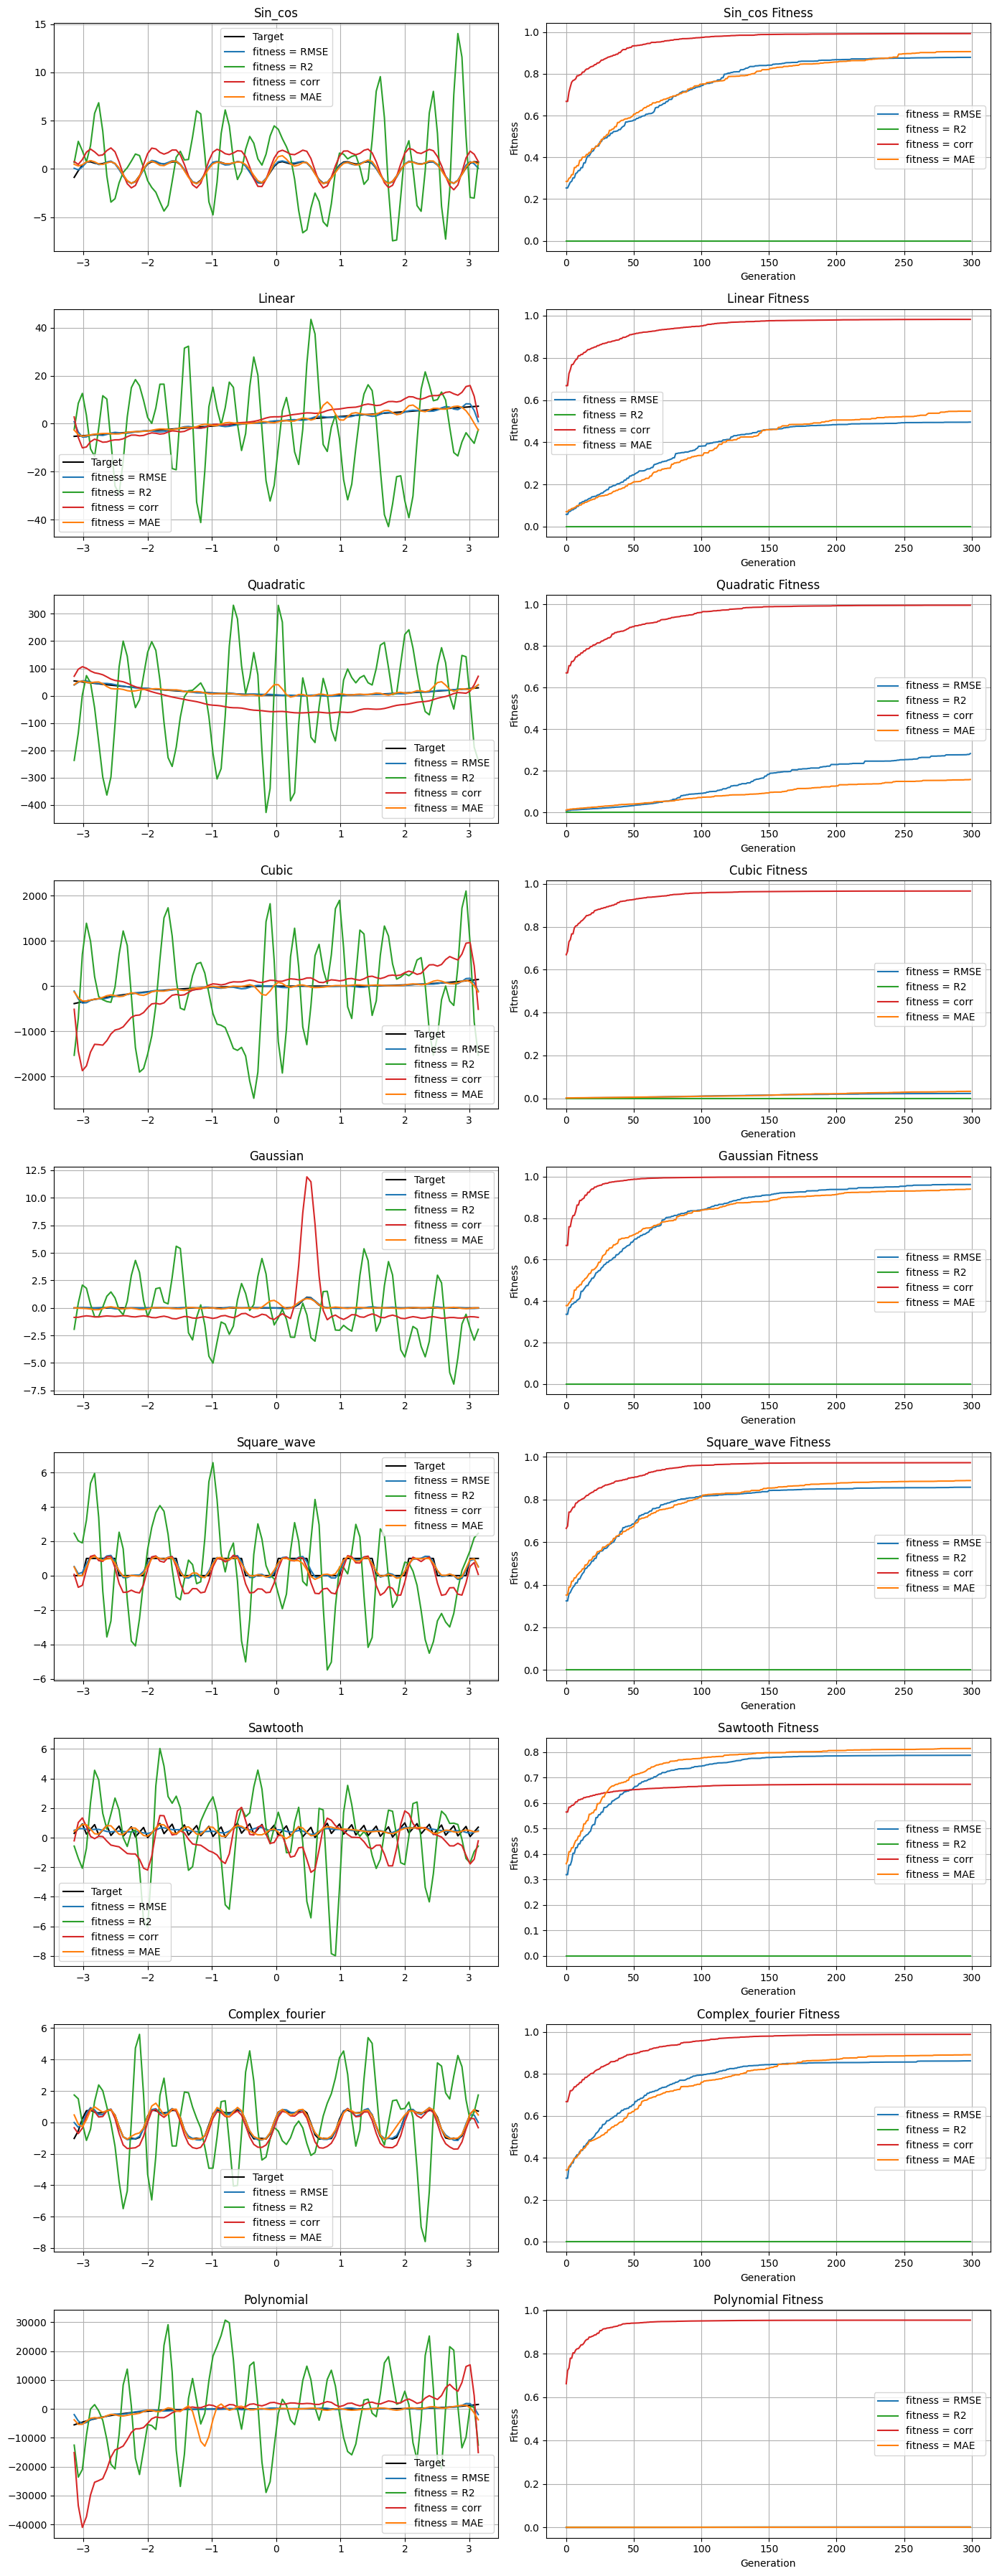

In [14]:
function_names = ["sin_cos", "linear", "quadratic", "cubic", "gaussian", "square_wave", "sawtooth", "complex_fourier", "polynomial"]
numRows = len(function_names)
numCols = 2
fig, axs = plt.subplots(numRows, numCols, figsize = (14, 4 * numRows))
colors = ['C0', 'C2', 'C3' ,'C1']

fitnessOptions = {
    "RMSE": calculate_RMSE,
    "R2": calculate_R2,
    "corr": calculate_corr,
    "MAE": calculate_MAE,
}
for i in range(len(function_names)):
    function_name = function_names[i]
    tSamples = np.linspace(functionRange[0], functionRange[1], sampleCount)
    fSamples = getTargetFunction(function_name)(tSamples)
    limitA = np.max(np.abs(fSamples))
    approximations = []
    fitness_histories = []    
    for fitness_option in fitnessOptions.values():
        approximation, fitness_history = GA(tsamples = tSamples, fsamples = fSamples, populationSize = 100 , fitness_func = fitness_option, crossover_func = uniform_crossover, selection_func = tournament_selection)    
        approximations.append(approximation)
        fitness_histories.append(fitness_history)

    axs[i, 0].plot(tSamples, fSamples, 'k-', label = "Target") 
    j = 0 
    for name in fitnessOptions.keys():
        axs[i, 0].plot(tSamples, approximations[j], color = colors[j], label = "fitness = " + name)
        j += 1
    axs[i, 0].set_title(function_name.capitalize())
    axs[i, 0].legend()
    axs[i, 0].grid(True)
    
    j = 0 
    for name in fitnessOptions.keys():
        axs[i, 1].plot(fitness_histories[j], color = colors[j], label = "fitness = " + name)
        j += 1
    axs[i, 1].set_title(function_name.capitalize() + " Fitness")
    axs[i, 1].set_xlabel("Generation")
    axs[i, 1].set_ylabel("Fitness")
    axs[i, 1].legend()
    axs[i, 1].grid(True)

plt.tight_layout()
plt.show()


# بخش ۳
#### همانطور که مشاهده میکنیم RMSE بهترین عملکرد را نسبت به R2, MAE ,corr دارد و این به خاطر این است که توان دویی که وجود دارد باعث میشود تا به ازای اختلاف های بزرگ با نمونه واقعی ارور خیلی بزرگتری بگیریم و فیتنس بیشتر روی اختثلاف های بزرگ حساس باشد. همچنین تابع ساده ای دارد و زمان بهینه ای دارد. 

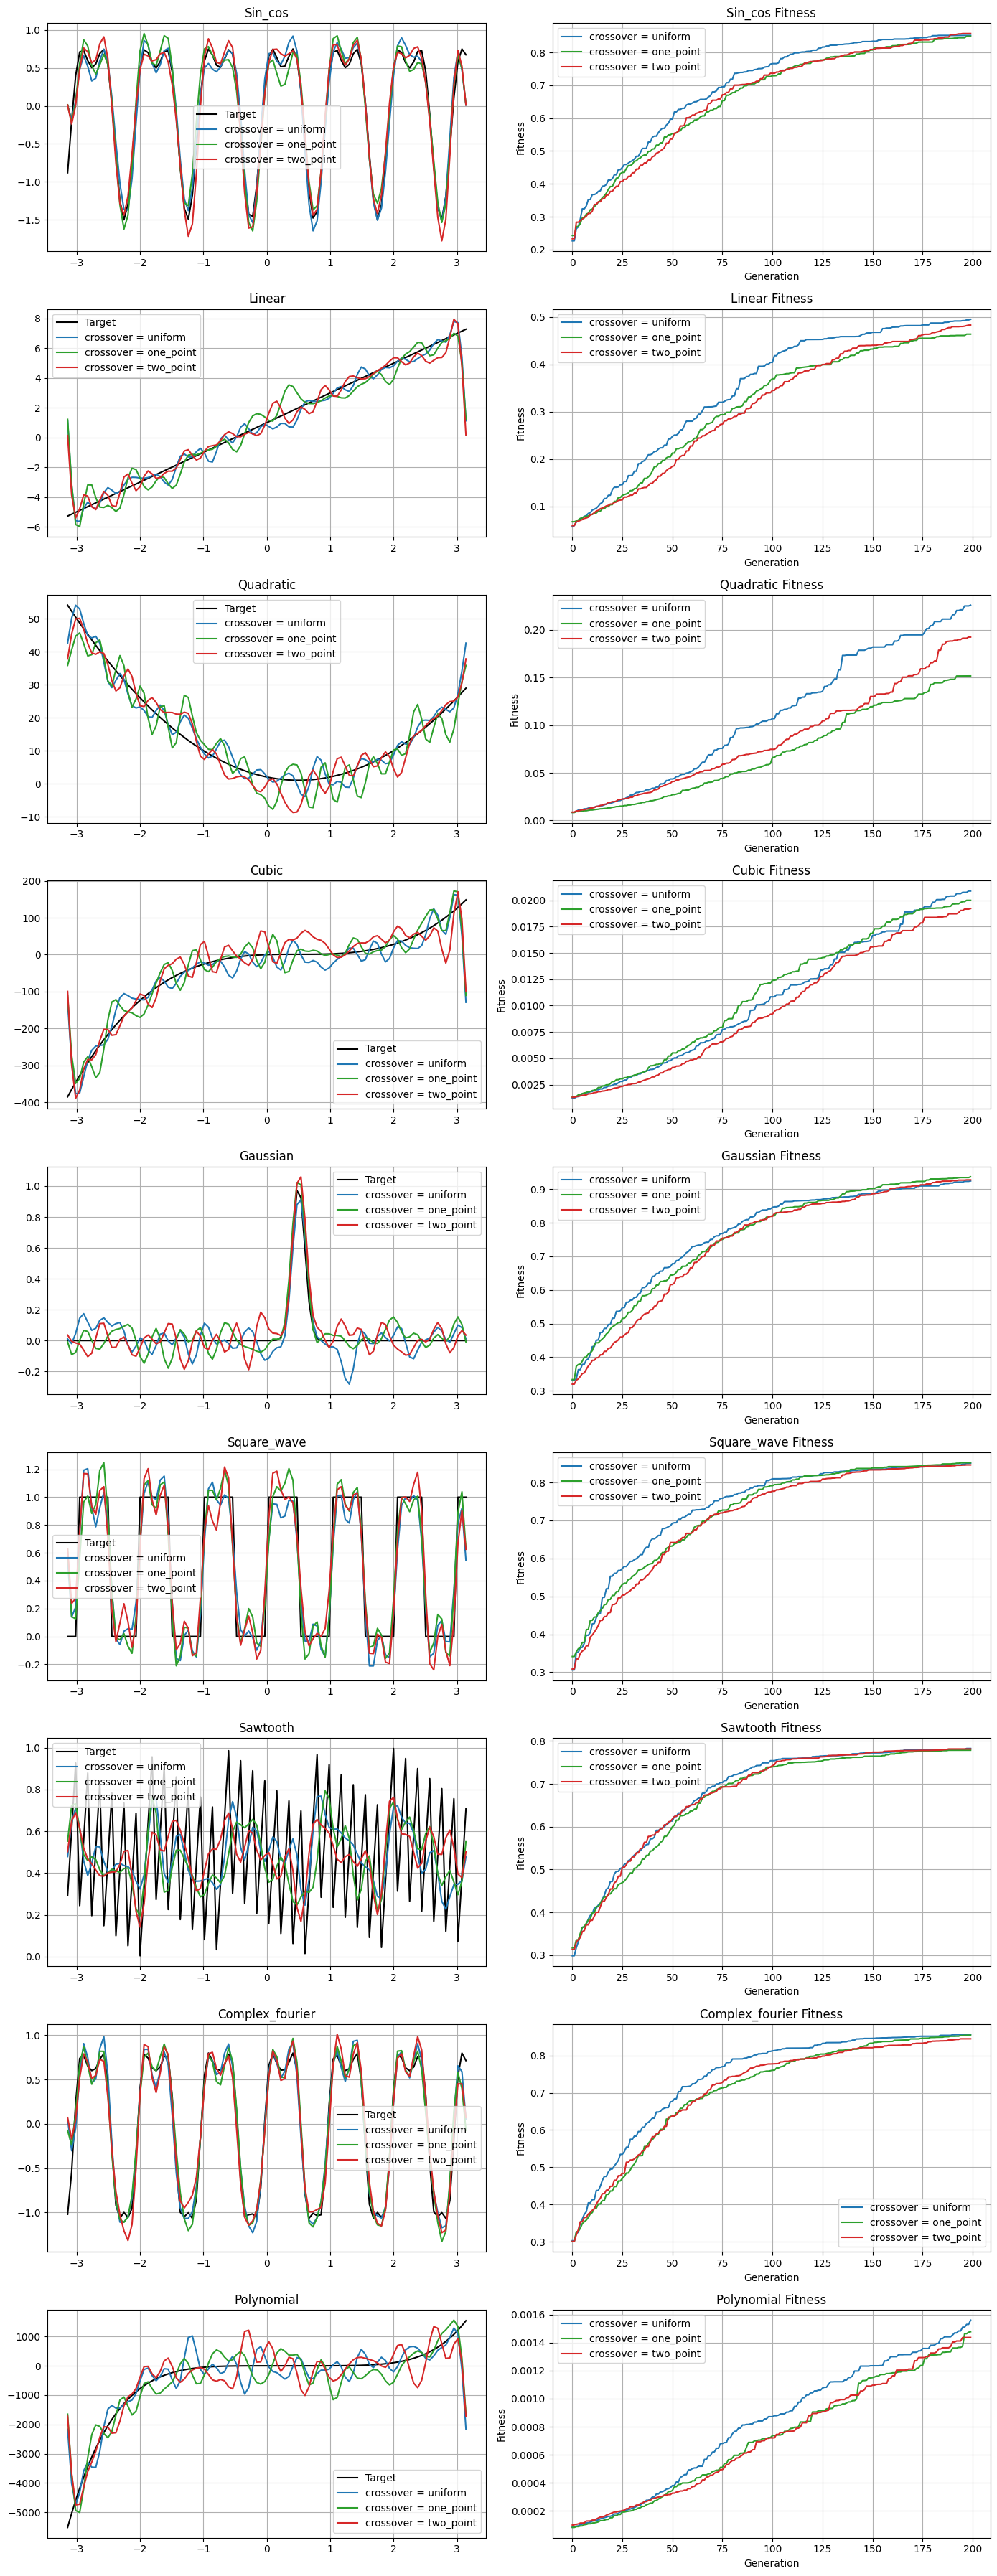

In [15]:
function_names = ["sin_cos", "linear", "quadratic", "cubic", "gaussian", "square_wave", "sawtooth", "complex_fourier", "polynomial"]
numRows = len(function_names)
numCols = 2
fig, axs = plt.subplots(numRows, numCols, figsize = (14, 4 * numRows))
colors = ['C0', 'C2', 'C3' ,'C1']

crossoverOptions = {
    "uniform": uniform_crossover,
    "one_point": one_point_crossover,
    "two_point": two_point_crossover,
}
for i in range(len(function_names)):
    function_name = function_names[i]
    tSamples = np.linspace(functionRange[0], functionRange[1], sampleCount)
    fSamples = getTargetFunction(function_name)(tSamples)
    limitA = np.max(np.abs(fSamples))
    approximations = []
    fitness_histories = []    
    for crossover_option in crossoverOptions.values():
        approximation, fitness_history = GA(num_generations = 200, tsamples = tSamples, fsamples = fSamples, populationSize = 100 , fitness_func = calculate_RMSE, crossover_func = crossover_option, selection_func = tournament_selection)    
        approximations.append(approximation)
        fitness_histories.append(fitness_history)

    axs[i, 0].plot(tSamples, fSamples, 'k-', label = "Target") 
    j = 0 
    for name in crossoverOptions.keys():
        axs[i, 0].plot(tSamples, approximations[j], color = colors[j], label = "crossover = " + name)
        j += 1
    axs[i, 0].set_title(function_name.capitalize())
    axs[i, 0].legend()
    axs[i, 0].grid(True)
    
    j = 0 
    for name in crossoverOptions.keys():
        axs[i, 1].plot(fitness_histories[j], color = colors[j], label = "crossover = " + name)
        j += 1
    axs[i, 1].set_title(function_name.capitalize() + " Fitness")
    axs[i, 1].set_xlabel("Generation")
    axs[i, 1].set_ylabel("Fitness")
    axs[i, 1].legend()
    axs[i, 1].grid(True)

plt.tight_layout()
plt.show()


# بخش ۴ انواع mutation ها 
####  در این بخش من ۳ نوع کراس اور را بررسی کردم و نتایج نشان میدهد که تاثیر زیادی بر روی نتیجه نهایی در تعداد جنریشن های معقول ندارد و اغلب نتیجه برابری داشتند. 

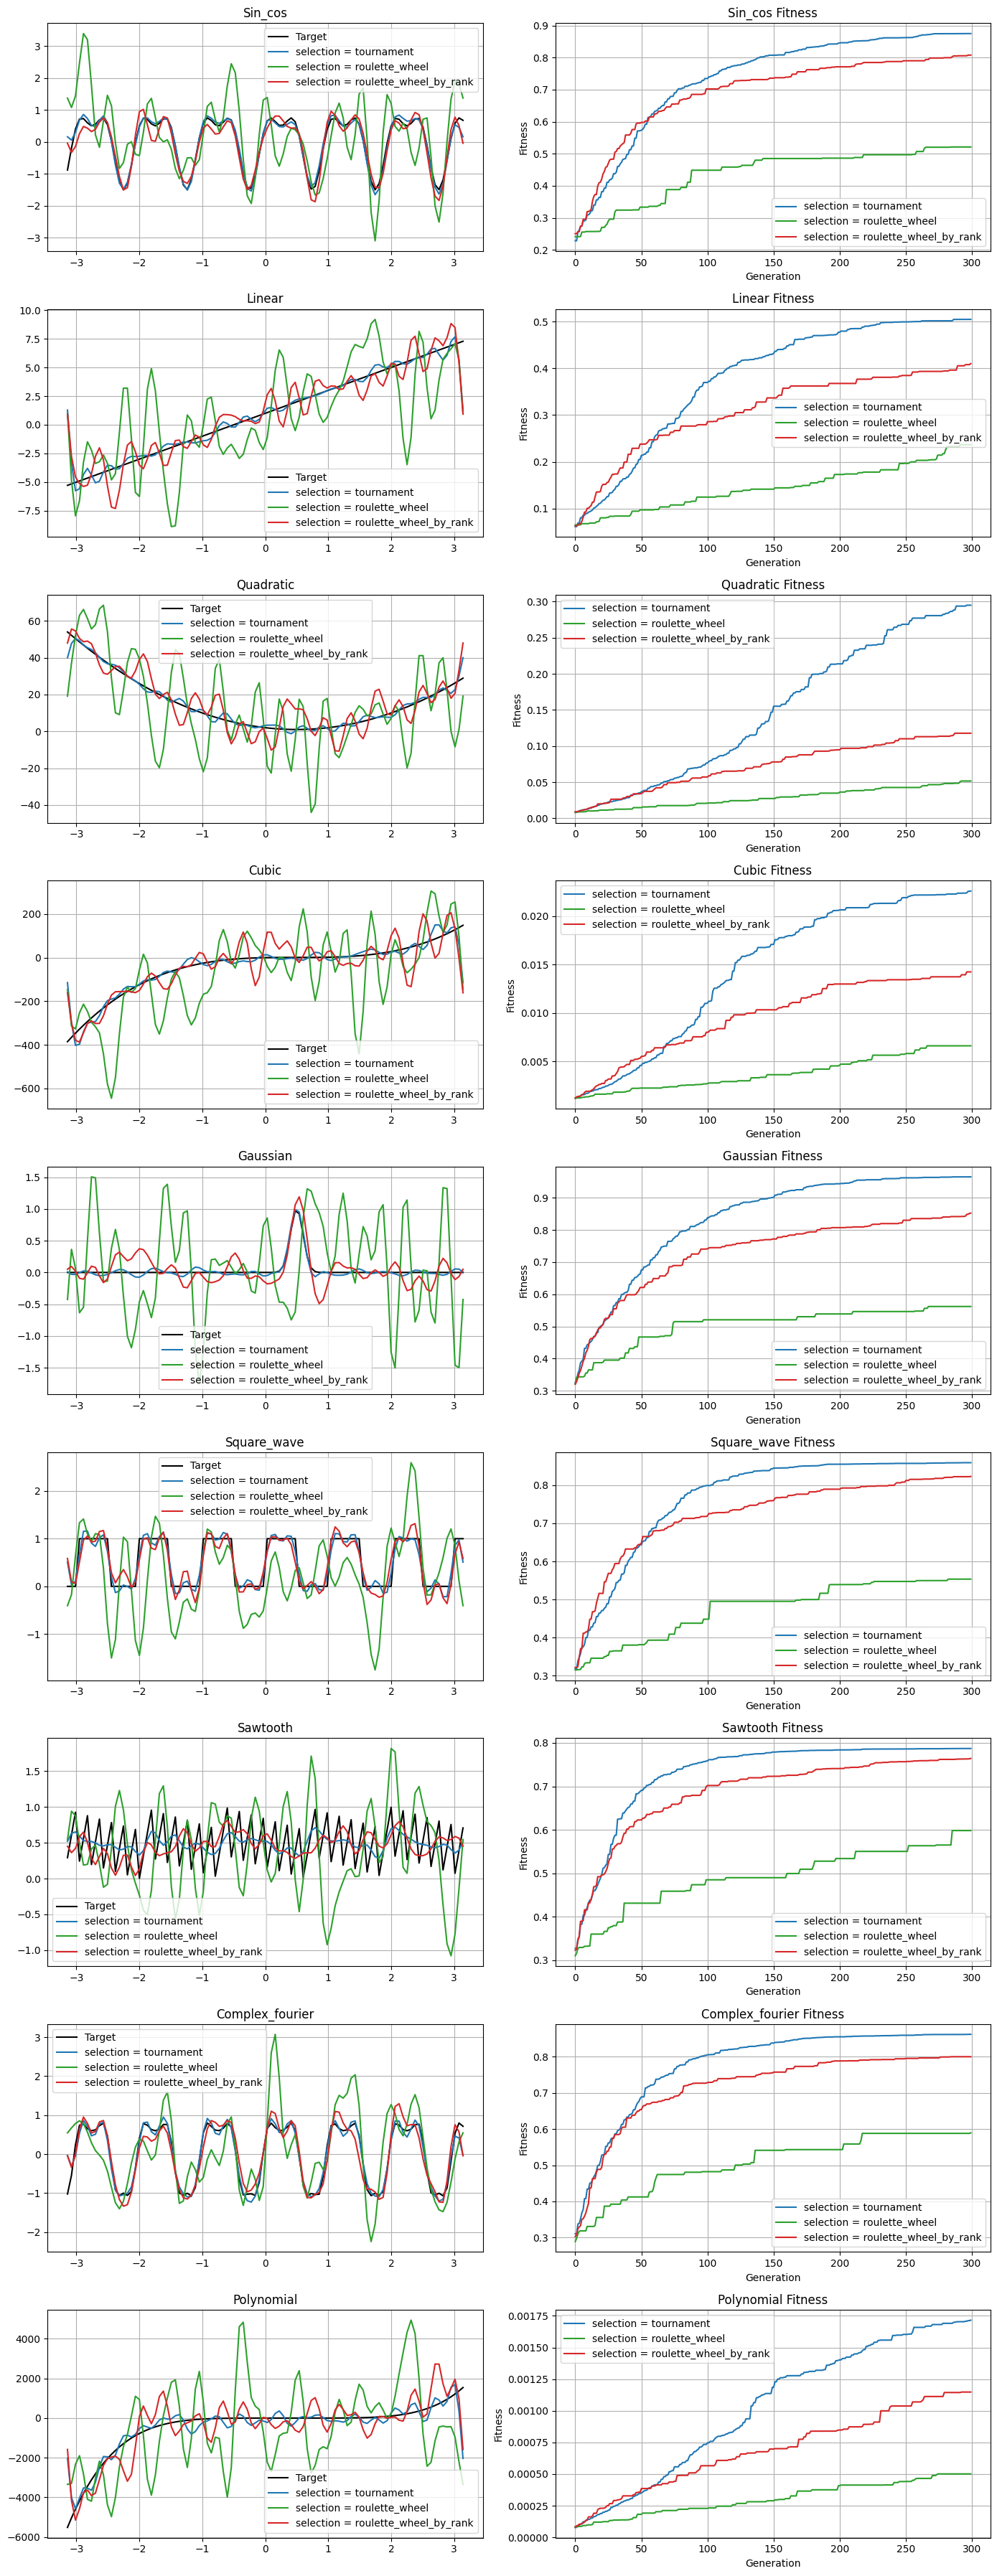

In [16]:
function_names = ["sin_cos", "linear", "quadratic", "cubic", "gaussian", "square_wave", "sawtooth", "complex_fourier", "polynomial"]
numRows = len(function_names)
numCols = 2
fig, axs = plt.subplots(numRows, numCols, figsize = (14, 4 * numRows))
colors = ['C0', 'C2', 'C3' ,'C1']

selectionOptions = {
    "tournament": tournament_selection,
    "roulette_wheel": roulette_wheel_selection,
    "roulette_wheel_by_rank": roulette_wheel_selection_by_rank,
}
for i in range(len(function_names)):
    function_name = function_names[i]
    tSamples = np.linspace(functionRange[0], functionRange[1], sampleCount)
    fSamples = getTargetFunction(function_name)(tSamples)
    limitA = np.max(np.abs(fSamples))
    approximations = []
    fitness_histories = []    
    for selection_option in selectionOptions.values():
        approximation, fitness_history = GA(num_generations = 300, tsamples = tSamples, fsamples = fSamples, populationSize = 100 , fitness_func = calculate_RMSE, crossover_func = uniform_crossover, selection_func = selection_option)    
        approximations.append(approximation)
        fitness_histories.append(fitness_history)

    axs[i, 0].plot(tSamples, fSamples, 'k-', label = "Target") 
    j = 0 
    for name in selectionOptions.keys():
        axs[i, 0].plot(tSamples, approximations[j], color = colors[j], label = "selection = " + name)
        j += 1
    axs[i, 0].set_title(function_name.capitalize())
    axs[i, 0].legend()
    axs[i, 0].grid(True)
    
    j = 0 
    for name in selectionOptions.keys():
        axs[i, 1].plot(fitness_histories[j], color = colors[j], label = "selection = " + name)
        j += 1
    axs[i, 1].set_title(function_name.capitalize() + " Fitness")
    axs[i, 1].set_xlabel("Generation")
    axs[i, 1].set_ylabel("Fitness")
    axs[i, 1].legend()
    axs[i, 1].grid(True)

plt.tight_layout()
plt.show()


# ادامه بخش ۴
### همانطور که مشاهده میکنیم متد دومی که اضافه کردیم خیلی ضعیف تر از تورنمنت عمل میکند و به این دلیل است که نیازمند تابع فیتنس مناسب برای اینکه توزیع احتمالی خوبی داشته باشد تا بتواند به خوبی نتجه دهد و من با تمام توابعی که بررسی کردم تست کردم اما نتیجه مطلوبی نگرفتم.

# بخش ۵ تحلیل و نتیجه ها
#### در این پروژه طبق آزمایش ها و نمودار هایی که بدست آوردیم نتیجه گرفتیم که مقدار میوتیشن باید در اردر یک درصد باشد تا نتیجه مطلوب داشته باشیم و اگر بیشتر باشد به احتمال خیلی زیاد اگر جمعیت خوبی هم ساخته شود در مرحله بعدی خراب میشود 
#### در گام بعدی هم بهترین فیتنس را از بین فیتنس هایی که امتحان کردیم فیتنس RMSE بدست آوردیم 
#### از میان استراتژی های انتخال نسل بعدی هم همین بالا دیدیم که ترنمنت روش خیلی خوبی است و در مقادیر پایین جنریشن به خوبی جواب میدهد اما روش رولت چرخ نیاز به جنریشن خیلی زیادی دارد تا به دقت قابل قبول برسد. 
#### همچنین نتیجه گرفتیم که هر چقدر جمعیت بیشتر باشد دقت ما بیشتر میشود و ما حالت های مختلف بیشتری را کاور میکنیم و احتمال بیشتری داریم تا به هدف برسیم. 
#### در روش های crossover هم که تست کردیم تفاوت چندانی وجود نداشت چون که تعداد جنریشن ها به میزانی بود که رندم بودن آنها در نسل های آخر تقریبا برابر میشد. 

# پرسش اول
#### فضای حالت کروموزوم ها را اینگونه محاسبه میکنیم:‌ هر کروموزوم از ۴۱ تا ژن تشکیل شده که هر ژن در بازه -A تا A در مجموعه اعداد حقیقی قرار دارد. و فضای کل حالات انگار یک ۴۱ تایی مرتب هست که هر عضوش در آن بازه A تا -A قرار دارد. از طرفی ما هم این مقدار را برابر بیشینه قدرمطلق مقادیر تابع واقعی قرار دادیم. 

# پرسش دوم
#### یک ایده این است که ما اگر راجب تابع هدف و سری فوریه آن تحقیق کنیم و ویژگی های آن را پیدا کنیم میتوانیم جمعیت اولیه متناسبی تشکیل بدیم تا سریع تر به سمت جواب بگراییم. 
#### ایده دوم هم این است که هر جا درون الگوریتم دیدیم که فیتنس ها تغییر خاصی نمیکنند میتوانیم میوتیشن ریت را تغییر بدهیم و اجازه بدهیم که الگوریتم بیشتر اشتباه کند و از جواب بهینه محلی خارج شود. در این صورت باعث میشود که در یه بهینه محلی گیر نیفتیم و سریع تر به هدف برسیم.

# پرسش سوم
#### یک استراتژی استراتژی ترنمنت است. به این صورت است که ما برای تولید یک بچه دو گروه از کروموزوم ها را به صورت رندوم انتخاب میکنیم و از بهترین های آن دو گروه از نظر فیتنس را با انجام عملیات کراس اور بچه را میسازیم. 
#### متد دیگر متد رولت چرخ میباشد که به هر یک از اعضای جمعیت آن یک احتمال به نسبت فیتنسی که به آن درنظر گرفته نسبت میدهیم و در نهایت با این توزیع احتمال ها به صورت تصادفی یک نفر به عنوان والد انتخاب میشود. 

# پرسش چهارم
#### اصولا برای اینکه در یک ماکسیمم محلی گیر نکنیم باید به هوش مصنوعی اجازه بدیم تا بتونه اشتباه بکنه و این اشتباه ها باعث باشه که از ماکسیمم محلی خارج بشه. به عنوان مثال میتونیم درصد میوتیشن ریت رو زیاد کنیم یا اصلا خود تابع میوتیشن را عوض میکنیم. 
#### همچنین میتوانیم جمعیت اولیه را به صورت هوشمند و تحقیق شده انتخاب کنیم تا مطمعن باشیم که از همان ابتدا تنوع در کروموزوم ها وجود دارد
#### در کل با تغییر دادن پارامتر های مسعله میتوانیم میزان تنوع رو تعیین کنیم مانند تعداد جمعیت. یا حتی میتوانیم در بعضی از نسل ها استراتژی سلکشن را عوض کنیم یا تورنمنت را ۱ عضوی بگیریم... یا از رولت چرخ استفاده کنیم. 

# پرسش پنجم
#### r_square نشان دهنده نسبت MSE پیشبینی شده توسط مدل تقسیم بر واریانس کل داده هاست. 
#### این مقدار خاصیتی که دارد این است که یک مقدار بین ۰ و ۱ دارد 
#### این مقدار هر چقدر به یک نزدیک شود یعنی اینکه مدل به بهترین شکل پیشبینی کرده و هرچه به سمت ۰ یا منفی تر میرود خیلی از نمونه دور میشود... همچنین این روش برای تابع هایی مناسب است که واریانس بالایی دارند تا مخرج بزرگتری در فرمول درست شود.

# <span style="color: #3498db;">Minmax Algorithm</span>

In [17]:
import random
import numpy as np
from math import inf
import time
import pygame

In [18]:
import random
import numpy as np
from math import inf
import time
import pygame
class PentagoGame:
    def __init__(self, ui=False, print=False, depth=2, pruning=False):
        self.pruning = pruning
        self.board = np.zeros((6, 6), dtype=int)
        self.current_player = 1
        self.ui = ui
        self.depth = depth
        self.nodes_visited = 0
        self.game_over = False
        self.result = None
        self.selected_block = None
        self.move_stage = 0  # 0: place piece, 1: select block, 2: rotate
        self.temp_piece = None
        self.print = print
        self.agent = -1
        self.player = 1
        self.player_weights = np.array([8, 80, 800, 8000])
        self.agent_weights = np.array([10, 100, 1000, 10000])
        self.diag5 = [[(1 + x, x) for x in range(5)], [(x, x + 1) for x in range(5)], [(5 - x, 1 + x) for x in range(5)], [(4 - x, x) for x in range(5)]]
        self.time_elapsed = 0
        self.num_nodes = 0 
        if ui:
            pygame.font.init()
            self.screen = pygame.display.set_mode((800, 600))
            pygame.display.set_caption("Pygame Board")
            # self.font = pygame.font.SysFont("Arial", 20)
            self.show_buttons = False
            self.buttons = {
                "rotate_cw": pygame.Rect(650, 200, 100, 50),
                "rotate_ccw": pygame.Rect(650, 300, 100, 50),
            }
            self.setup_controls()
            self.draw_board()

    def get_time_elapsed(self):
        return self.time_elapsed
    def get_num_nodes(self):
        return self.num_nodes

    def setup_controls(self):
        if self.show_buttons:
            pygame.draw.rect(self.screen, (144, 238, 144), self.buttons["rotate_cw"])   # Light Green
            pygame.draw.rect(self.screen, (173, 216, 230), self.buttons["rotate_ccw"])  # Light Blue

            self.screen.draw_text("CLOCKWISE", self.buttons["rotate_cw"].center)
            self.screen.draw_text("COUNTER-CLOCKWISE", self.buttons["rotate_ccw"].center)

    def hide_rotation_buttons(self):
        self.show_buttons = False

    def show_rotation_buttons(self):
        self.show_buttons = True

    def copy_board(self, board):
        return np.copy(board)

    def rotate_block(self, board, block, direction):
        row_start = (block // 2) * 3
        col_start = (block % 2) * 3
        sub = board[row_start : row_start + 3, col_start : col_start + 3]
        rotated = np.rot90(sub, 3 if direction == "cw" else 1)
        board[row_start : row_start + 3, col_start : col_start + 3] = rotated

    def get_possible_moves(self, board, player):
        moves = []
        for i in range(6):
            for j in range(6):
                if board[i][j] == 0:
                    for block in range(4):
                        for dir in ["cw", "ccw"]:
                            moves.append((i, j, block, dir))
        return moves

    def apply_move(self, board, move, player):
        new_board = self.copy_board(board)
        row, col, block, direction = move
        if new_board[row][col] != 0:
            return None
        new_board[row][col] = player
        self.rotate_block(new_board, block, direction)
        return new_board

    def check_winner(self, board):
        for i in range(6):
            for j in range(6):
                if board[i][j] == 0:
                    continue

                # Horizontal
                if j <= 1 and np.all(board[i, j : j + 5] == board[i][j]):
                    return board[i][j]

                # Vertical
                if i <= 1 and np.all(board[i : i + 5, j] == board[i][j]):
                    return board[i][j]

                # Diagonal
                if (
                    i <= 1
                    and j <= 1
                    and all(board[i + k][j + k] == board[i][j] for k in range(5))
                ):
                    return board[i][j]

                # other-diagonal
                if (
                    i <= 1
                    and j >= 4
                    and all(board[i + k][j - k] == board[i][j] for k in range(5))
                ):
                    return board[i][j]
        if np.all(board != 0):
            return 0
        return None
    
    def heuristic(self, state):
        winner = self.check_winner(state)
        if winner == self.agent:
            return inf
        if winner == self.player:
            return -inf
        num_ball_player = np.zeros(6)
        num_ball_agent = np.zeros(6)
        for i in range(6):
            row_agent = np.count_nonzero(state[i] == self.agent)
            row_player = np.count_nonzero(state[i] == self.player)
            col_agent = np.count_nonzero(state[:, i] == self.agent)
            col_player = np.count_nonzero(state[:, i] == self.player)
            if row_agent > 1: num_ball_agent[row_agent] += 1
            elif 1 < row_player: num_ball_player[row_player] += 1
            if col_agent > 1: num_ball_agent[col_agent] += 1
            elif 1 < col_player: num_ball_player[col_player] += 1
        
        main_diag = [state[i][i] for i in range(6)]
        other_diag = [state[i][5 - i] for i in range(6)]
        main_diag_agent = main_diag.count(self.agent)
        main_diag_player = main_diag.count(self.player)
        other_diag_agent = other_diag.count(self.agent)
        other_diag_player = other_diag.count(self.player)
        if 1 < main_diag_agent:
            num_ball_agent[main_diag_agent] += 1
        elif main_diag_player > 1:
            num_ball_player[main_diag_player] += 1
        if 1 < other_diag_agent:
            num_ball_agent[other_diag_agent] += 1
        elif other_diag_player > 1:
            num_ball_player[other_diag_player] += 1
        
        for diag in self.diag5:
            agent_count = sum(state[i][j] == self.agent for i, j in diag)
            player_count = sum(state[i][j] == self.player for i, j in diag)
            if agent_count > 1:
                num_ball_agent[agent_count] += 1
            elif player_count > 1:
                num_ball_player[player_count] += 1
            
        player_score = np.dot(self.player_weights, num_ball_player[2:6])
        agent_score = np.dot(self.agent_weights, num_ball_agent[2:6])
        return agent_score - player_score

    def minimax(self, minimizing, alpha, beta, state, depth):
        self.nodes_visited += 1
        winner = self.check_winner(state)
        if winner == self.agent:
            return inf
        if winner == self.player:
            return -inf
        if depth == 0: 
            return self.heuristic(state)
        if minimizing:
            min_answer = inf
            moves = self.get_possible_moves(state, self.player)
            for move in moves: 
                next_state = self.apply_move(state, move, self.player)
                if next_state is None:
                    continue
                max_child = self.minimax(False, alpha, beta, next_state, depth - 1)
                min_answer = min(min_answer, max_child)
                beta = min(beta, max_child)
                if (self.pruning and beta <= alpha): 
                    break
            return min_answer
        else:
            max_answer = -inf
            moves = self.get_possible_moves(state, self.agent)
            for move in moves: 
                next_state = self.apply_move(state, move, self.agent)
                if next_state is None: 
                    continue
                min_child = self.minimax(True, alpha, beta, next_state, depth - 1)
                max_answer = max(max_answer, min_child)
                alpha = max(alpha, min_child)
                if (self.pruning and beta <= alpha):
                    break
            return max_answer
            


    def get_computer_move(self):
        start_time = time.time()
        best_move = None
        best_value = -inf
        
        moves = self.get_possible_moves(self.board, -1)
        if not moves:
            return None
        best_move = moves[0]
        alpha = -inf
        beta = inf

        for move in moves:
            if self.game_over:
                break
            new_board = self.apply_move(self.board, move, -1)
            if new_board is None:
                continue
            try:
                value = self.minimax(minimizing = True, alpha = alpha, beta = beta, state = new_board, depth = self.depth - 1)
                alpha = max(alpha, value)
            except:
                value = -inf

            if value > best_value:
                best_value = value
                best_move = move
        self.num_nodes += self.nodes_visited
        self.time_elapsed += time.time()-start_time
        if self.print == True:    
            print(f"Move took {time.time()-start_time:.2f}s, nodes visited: {self.nodes_visited}")
        self.nodes_visited = 0
        return best_move

    def draw_text(self, text, center_pos, max_width):
        font_size = 24
        font = pygame.font.Font(None, font_size)
        text_surface = font.render(text, True, (0, 0, 0))

        text_width = text_surface.get_width()
        if text_width > max_width:
            scale_factor = max_width / text_width
            new_font_size = int(font_size * scale_factor)
            font = pygame.font.Font(None, new_font_size)
            text_surface = font.render(text, True, (0, 0, 0))

        text_rect = text_surface.get_rect(center=center_pos)
        self.screen.blit(text_surface, text_rect)

    def draw_board(self):
        self.screen.fill((0, 0, 0))

        for i in range(6):
            for j in range(6):
                x0 = j * 100
                y0 = i * 100

                if self.board[i][j] == 1:
                    pygame.draw.circle(self.screen, (255, 0, 0), (x0 + 50, y0 + 50), 40)
                elif self.board[i][j] == -1:
                    pygame.draw.circle(self.screen, (0, 0, 255), (x0 + 50, y0 + 50), 40)

                pygame.draw.rect(self.screen, (255, 255, 255), (x0, y0, 100, 100), 1)

        for i in [3, 6]:
            pygame.draw.line(self.screen, (255, 255, 255), (0, i * 100), (600, i * 100), 3)  # Horizontal
            pygame.draw.line(self.screen, (255, 255, 255), (i * 100, 0), (i * 100, 600), 3)  # Vertical

        # Show rotation buttons if in move_stage 2
        if self.move_stage == 2:
            self.highlight_selected_block()
            self.show_rotation_buttons()

        if self.show_buttons:
            pygame.draw.rect(self.screen, (144, 238, 144), self.buttons["rotate_cw"])  # Light Green
            pygame.draw.rect(self.screen, (173, 216, 230), self.buttons["rotate_ccw"])  # Light Blue

            self.draw_text(
                "CLOCKWISE",
                self.buttons["rotate_cw"].center,
                self.buttons["rotate_cw"].width,
            )
            self.draw_text(
                "COUNTER-CLOCKWISE",
                self.buttons["rotate_ccw"].center,
                self.buttons["rotate_ccw"].width,
            )

    def click_handler(self, event):
        if self.game_over or self.current_player != 1:
            return

        x, y = event.pos
        if self.move_stage == 0:  # Place piece
            if x > 600:
                return  # clicks on control area
            col = x // 100
            row = y // 100
            if 0 <= row < 6 and 0 <= col < 6 and self.board[row][col] == 0:
                self.temp_piece = (row, col)
                self.board[row][col] = 1
                self.move_stage = 1
                self.draw_board()

        elif self.move_stage == 1:  # Select block
            if x > 600:
                return
            # which block was clicked
            block_x = 0 if x < 300 else 1
            block_y = 0 if y < 300 else 1
            self.selected_block = block_y * 2 + block_x
            self.move_stage = 2
            self.show_rotation_buttons()
            self.highlight_selected_block()

        elif self.move_stage == 2:  # Rotate
            if self.buttons["rotate_cw"].collidepoint(event.pos):
                self.apply_rotation("cw")
            if self.buttons["rotate_ccw"].collidepoint(event.pos):
                self.apply_rotation("ccw")

    def apply_rotation(self, direction):
        self.rotate_block(self.board, self.selected_block, direction)
        self.current_player = -1
        self.move_stage = 0
        self.selected_block = None
        self.temp_piece = None
        self.hide_rotation_buttons()
        self.draw_board()
        pygame.display.flip()
        self.check_game_over()
        pygame.time.delay(1000)
        self.play_computer_move()

    def highlight_selected_block(self):
        colors = [
            (255, 153, 153),
            (153, 255, 153),
            (153, 153, 255),
            (255, 255, 153),
        ]  # RGB colors

        row_start = (self.selected_block // 2) * 3
        col_start = (self.selected_block % 2) * 3

        pygame.draw.rect(
            self.screen,
            colors[self.selected_block],
            (col_start * 100, row_start * 100, 300, 300),
            5,
        )

    def play_computer_move(self):
        move = self.get_computer_move()
        if move and not self.game_over:
            new_board = self.apply_move(self.board, move, -1)
            if new_board is not None:
                self.board = new_board
                self.current_player = 1
                self.draw_board()
                pygame.display.flip()
                self.check_game_over()
            else:
                print("Invalid computer move!")

    def check_game_over(self):
        winner = self.check_winner(self.board)
        if winner is not None:
            self.game_over = True
            self.result = winner
            print("Game over! Result:", winner)
            if self.ui:
                self.show_game_over_message()

    def show_game_over_message(self):
        self.screen.fill((200, 200, 200))
        pygame.draw.rect(self.screen, (255, 255, 255), (100, 200, 500, 200))
        pygame.draw.rect(self.screen, (0, 0, 0), (100, 200, 500, 200), 3)

        result_text = f"Player {self.result} wins!" if self.result != 0 else "Draw!"
        text_surface = self.font_large.render(result_text, True, (255, 0, 0))
        self.screen.blit(text_surface, (250, 250))

        exit_text = self.font_small.render("Click anywhere to exit", True, (0, 0, 0))
        self.screen.blit(exit_text, (230, 350))
        pygame.display.flip()

    def play(self):
        if self.ui:
            running = True
            while running:
                for event in pygame.event.get():
                    if event.type == pygame.QUIT:
                        running = False
                    elif event.type == pygame.MOUSEBUTTONDOWN:
                        self.click_handler(event)
                self.draw_board()
                pygame.display.flip()
            pygame.quit()
            return self.result
        else:
            while not self.game_over:
                self.print_board()
                winner = self.check_winner(self.board)
                if winner is not None:
                    return winner

                if self.current_player == 1:
                    move = random.choice(self.get_possible_moves(self.board, 1))
                else:
                    move = self.get_computer_move()

                self.board = self.apply_move(self.board, move, self.current_player)
                self.current_player *= -1
            return self.result

    def print_board(self):
        if self.print == False:
            return
        print("-" * 25)
        for row in self.board:
            print(" ".join(f"{x:2}" for x in row))
        print("-" * 25)

# Without pruning Depth 1

In [19]:
game = PentagoGame(ui=False, print=False, depth=1, pruning = False)  # depth=2 for faster
numGames = 50
numWins, numTies, numLosses = 0, 0, 0
time_elapsed = 0
num_nodes = 0
for i in range(numGames):
    result = game.play()
    if result == -1:
        numWins += 1
    elif result == 0:
        numTies += 1
    else:
        numLosses += 1
    time_elapsed += game.get_time_elapsed()
    num_nodes += game.get_num_nodes()
print(f"{numWins} wins, {numTies} ties, {numLosses} losses")
print("mean time: ", time_elapsed / numGames)
print("mean visited nodes: ", num_nodes / numGames)
print("prob of success: ", numWins / numGames)

50 wins, 0 ties, 0 losses
mean time:  0.19074106216430664
mean visited nodes:  1440.0
prob of success:  1.0


# Without pruning Depth 2

In [20]:
game = PentagoGame(ui=False, print=False, depth=2, pruning = False)  # depth=2 for faster
numGames = 50
numWins, numTies, numLosses = 0, 0, 0
time_elapsed = 0
num_nodes = 0
for i in range(numGames):
    result = game.play()
    if result == -1:
        numWins += 1
    elif result == 0:
        numTies += 1
    else:
        numLosses += 1
    time_elapsed += game.get_time_elapsed()
    num_nodes += game.get_num_nodes()
print(f"{numWins} wins, {numTies} ties, {numLosses} losses")
print("mean time: ", time_elapsed / numGames)
print("mean visited nodes: ", num_nodes / numGames)
print("prob of success: ", numWins / numGames)

50 wins, 0 ties, 0 losses
mean time:  40.97088027000427
mean visited nodes:  372216.0
prob of success:  1.0


# Without pruning depth 3
#### جواب نمیدهد

# With pruning depth 1

In [21]:
game = PentagoGame(ui=False, print=False, depth=1, pruning = True)  # depth=2 for faster
numGames = 50
numWins, numTies, numLosses = 0, 0, 0
time_elapsed = 0
num_nodes = 0
for i in range(numGames):
    result = game.play()
    if result == -1:
        numWins += 1
    elif result == 0:
        numTies += 1
    else:
        numLosses += 1
    time_elapsed += game.get_time_elapsed()
    num_nodes += game.get_num_nodes()
print(f"{numWins} wins, {numTies} ties, {numLosses} losses")
print("mean time: ", time_elapsed / numGames)
print("mean visited nodes: ", num_nodes / numGames)
print("prob of success: ", numWins / numGames)

50 wins, 0 ties, 0 losses
mean time:  0.13676047325134277
mean visited nodes:  1240.0
prob of success:  1.0


# With pruning depth 2

In [22]:
game = PentagoGame(ui=False, print=False, depth=2, pruning = True)  # depth=2 for faster
numGames = 50
numWins, numTies, numLosses = 0, 0, 0
time_elapsed = 0
num_nodes = 0
for i in range(numGames):
    result = game.play()
    if result == -1:
        numWins += 1
    elif result == 0:
        numTies += 1
    else:
        numLosses += 1
    time_elapsed += game.get_time_elapsed()
    num_nodes += game.get_num_nodes()
print(f"{numWins} wins, {numTies} ties, {numLosses} losses")
print("mean time: ", time_elapsed / numGames)
print("mean visited nodes: ", num_nodes / numGames)
print("prob of success: ", numWins / numGames)

50 wins, 0 ties, 0 losses
mean time:  3.920229196548462
mean visited nodes:  31028.0
prob of success:  1.0


# With pruning depth 3 

In [23]:
game = PentagoGame(ui=False, print=False, depth=3, pruning = True)  # depth=2 for faster
numGames = 1
numWins, numTies, numLosses = 0, 0, 0
time_elapsed = 0
num_nodes = 0
for i in range(numGames):
    result = game.play()
    if result == -1:
        numWins += 1
    elif result == 0:
        numTies += 1
    else:
        numLosses += 1
    time_elapsed += game.get_time_elapsed()
    num_nodes += game.get_num_nodes()
print(f"{numWins} wins, {numTies} ties, {numLosses} losses")
print("mean time: ", time_elapsed / numGames)
print("mean visited nodes: ", num_nodes / numGames)
print("prob of success: ", numWins / numGames)

1 wins, 0 ties, 0 losses
mean time:  98.04388737678528
mean visited nodes:  1007424.0
prob of success:  1.0


### همانطور که میبینیم برای یک بازی حدود یک دقیقه طول کشید 

# Playing with random bot

In [24]:
game = PentagoGame(ui=False, print=False, depth=2, pruning = True)  # depth=2 for faster
numGames = 100
numWins, numTies, numLosses = 0, 0, 0
time_elapsed = 0
num_nodes = 0
for i in range(numGames):
    result = game.play()
    if result == -1:
        numWins += 1
    elif result == 0:
        numTies += 1
    else:
        numLosses += 1
    time_elapsed += game.get_time_elapsed()
    num_nodes += game.get_num_nodes()
print(f"{numWins} wins, {numTies} ties, {numLosses} losses")
print("mean time: ", time_elapsed / numGames)
print("mean visited nodes: ", num_nodes / numGames)
print("prob of success: ", numWins / numGames)

100 wins, 0 ties, 0 losses
mean time:  2.467599630355835
mean visited nodes:  23098.0
prob of success:  1.0


# Question 1: 
#### بله میان آنها ارتباط مستقیم و معکوس وجود دارد. به عنوان مثال اگر ما عمق بیشتری را بررسی کنیم منطقا احتمال برد ما بیشتر میشود و کمتر اشتباه میکنیم. 
#### اما هر چقدر که عمق بیشتر میشود زمان بیشتری طول میکشد تا ربات بازی کند. به این خاطر هست که در هر مرحله از محاسبات باید تعداد حالت های بیشتری را بررسی کند و تعداد نود بیشتری ببیند... 

# Question 2:
#### برای اینکه بتوانیم پیشبینی کنیم که چه ترتیبی از نود ها بیشترین هرس را به ما میدهد نیاز داریم مقدار هیوریستیک آن راس ها را بدانیم و خب بدون اجرای الگوریتم ما هیچ اطلاعاتی درباره راس ها نداریم. بنابراین نمیتوانیم قبل از اجرای الگوریتم بهترین ترتیب را پیدا کنیم

# Question 3: 
#### برنچینگ فاکتور برابر است با تعداد شاخه هایی که از یک نود آویزان میشوند. در این بازی تعداد حالات چرخش ها برابر ۸ است و تعداد خانه هایی که میتوان در آن مهره قرار داد حداکثر ۳۶ است که  هر مرحله یک واحد از ان کم میشود. پس در هر نود حاصل ضرب ۸ در تعداد خانه های خالی میشود برنچینگ فاکتور که کاهشی است. 

# Question 4:
#### در روش حرص کردن ما دو تا پارامتر الفا و بتا داریم که دو مقدار min و max ای که تا کنون از راس های دیده شده تا ریشه را که پیدا شده هر مرحله ذخیره و آپدیت میکنند. این اطلاعات به ما کمک میکند تا مثلا اگر در راسی هستیم و به یک مقداری برسیم که بدانیم دیگر این راس هیچ تاثیری روی عدد ریشه  نمیگذارد دیدن بقیه بچه های این راس کاری اضافی است و با توجه به پارامتر های آلفا و بتا بر حسب اینکه در نود مینیمایز یا ماکسیماز هستیم حرص کردن را تشخیص میدهیم. 

# Question 5:
#### این الگوریتم از آن جایی که زمان بیشتری مصرف میکند تا احتمال برد ما را در صورت هوشمند بازی کردن حریف افزایش دهد. درصورتی که حریف هوشمند نباشد و رندم بازی کند ما میتوانیم از الگوریتمی که امیدریاضی امتیاز بیشتری میگیرد استفاده کنیم و روی اینکه احتمال بردمان بالا هست اطمینان میکنیم. اینطوری زمان خیلی کمتری مصرف میکنیم و حتی ممکن هست در همان حرکات ابتدایی بازی به سرعت برنده شویم. 